<a href="https://colab.research.google.com/github/hoangmaituanhiep/2627I_DSA_10_HoangMaiTuanHiep/blob/main/notebooks/colab_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
import torch
import tensorflow as tf
from google.colab import drive
drive.mount("/content/drive")

In [ ]:
import os

DRIVE_ROOT = "/content/drive/MyDrive/DangerZoneDetection"
DATA_ZIP   = f"{DRIVE_ROOT}/data/FER2013.zip"
RUNS_DIR   = f"{DRIVE_ROOT}/runs"
MODELS_DIR = f"{DRIVE_ROOT}/models"
LOCAL_DATA = "/content/fer_plus"   # nơi giải nén (ổ cục bộ của Colab, đọc nhanh)

for d in (RUNS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.exists(DATA_ZIP), f"Không tìm thấy {DATA_ZIP}. Kiểm tra lại đã upload zip lên Drive chưa."

In [ ]:
REPO     = "https://github.com/hoangmaituanhiep/DangerZoneDetection.git"
REPO_DIR = "/content/DangerZoneDetection"

if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO} {REPO_DIR}

%cd {REPO_DIR}

if not os.path.exists(LOCAL_DATA):
    !cp "{DATA_ZIP}" /content/FER2013.zip
    !unzip -q /content/FER2013.zip -d {LOCAL_DATA}
else:
    !rm -rf /content/fer_plus/
    !cp "{DATA_ZIP}" /content/FER2013.zip
    !unzip -q /content/FER2013.zip -d {LOCAL_DATA}

!ls {LOCAL_DATA}

In [ ]:
import glob
import pandas as pd

train_dirs = glob.glob(f"{LOCAL_DATA}/**/FER2013Train", recursive=True)
assert train_dirs, "Không thấy thư mục FER2013Train trong dữ liệu đã giải nén."
BASE = os.path.dirname(train_dirs[0])
print("Thư mục gốc dữ liệu:", BASE)

SPLITS = {"train": "FER2013Train", "val": "FER2013Valid", "test": "FER2013Test"}
EMOTIONS = ["neutral", "happiness", "surprise", "sadness", "anger", "disgust", "fear", "contempt"]
VOTE_COLS = EMOTIONS + ["unknown", "NF"]

def load_split(folder):
    # label.csv: tên ảnh, khung mặt, rồi 10 cột số phiếu (không có dòng tiêu đề)
    df = pd.read_csv(f"{BASE}/{folder}/label.csv", header=None)
    df.columns = ["image", "box"] + VOTE_COLS
    votes = df[VOTE_COLS].values
    top = votes.argmax(axis=1)
    df["label_id"] = top
    df = df[df["label_id"] < len(EMOTIONS)].copy()          # bỏ unknown / NF
    df["label"] = df["label_id"].map(lambda i: EMOTIONS[i])
    df["path"] = f"{BASE}/{folder}/" + df["image"]
    return df.reset_index(drop=True)

dfs = {name: load_split(folder) for name, folder in SPLITS.items()}

for name, df in dfs.items():
    print(f"\n== {name}: {len(df)} ảnh ==")
    print(df["label"].value_counts().to_string())

# kiểm tra file ảnh có thật
missing = [p for p in dfs["train"]["path"].head(200) if not os.path.exists(p)]
print("\nẢnh bị thiếu (trong 200 ảnh đầu của train):", len(missing))

In [ ]:
train = pd.DataFrame(dfs['train'])
val = pd.DataFrame(dfs['val'])
test = pd.DataFrame(dfs['test'])
print(train['image'])
print(train['label'])
print(pd.unique(train['label']))

In [ ]:
print(pd.unique(train['label']))

In [ ]:
import matplotlib.pyplot as plt
def plot_learning_curve(history, model_name="Model"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    epochs = range(1, len(history.history['loss']) + 1)

    # --- Loss ---
    ax1.plot(epochs, history.history['loss'],     label='Train Loss')
    ax1.plot(epochs, history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'{model_name} — Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # --- Accuracy ---
    ax2.plot(epochs, history.history['accuracy'],     label='Train Accuracy')
    ax2.plot(epochs, history.history['val_accuracy'], label='Val Accuracy')
    ax2.set_title(f'{model_name} — Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
train['label'] = le.fit_transform(train['label'])
val['label'] = le.transform(val['label'])
test['label'] = le.transform(test['label'])
res = test['label'].values
test = test.drop(columns=['label'])

In [ ]:
IMG_SIZE = 48
BATCH = 128
NUM_CLASSES = len(EMOTIONS)
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(df, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label_id"].values.astype("int32"))
    )

    def load(path, y):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=1)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return tf.cast(img, tf.uint8), y

    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(dfs["train"], training=True)
val_ds   = make_ds(dfs["val"],   training=False)
test_ds  = make_ds(dfs["test"],  training=False)

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = dfs['train']['label_id'].values
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
weights = dict(enumerate(cw))

In [ ]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomTranslation(0.08, 0.08),
    tf.keras.layers.RandomZoom(0.1)
], name='augment')

def build_baseline():
  inputs = tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 1))
  x = tf.keras.layers.Rescaling(1/255.0) (inputs)
  x = augment(x)
  for f in (32, 64, 128, 256):
    for _ in range(2):
      x = tf.keras.layers.Conv2D(f, 3, padding='same', activation='relu') (x)
      x = tf.keras.layers.BatchNormalization() (x)
      x = tf.keras.layers.ReLU() (x)
    x = tf.keras.layers.MaxPooling2D() (x)
    x = tf.keras.layers.Dropout(0.4) (x)
  x = tf.keras.layers.GlobalAveragePooling2D() (x)
  x = tf.keras.layers.Dense(256, activation='relu') (x)
  x = tf.keras.layers.Dropout(0.4) (x)
  outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax') (x)
  return tf.keras.Model(inputs, outputs, name='baseline')

model = build_baseline()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

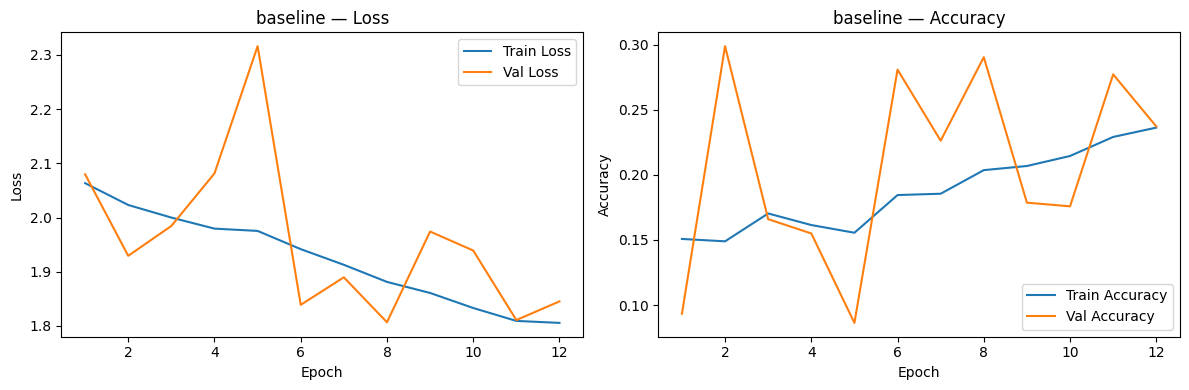

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.2722 - loss: 1.9346


In [ ]:
run_name = 'baseline'
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/best.keras', monitor='val_accuracy', save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=4, verbose=0),
    tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')
]

his = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks, class_weight=weights, verbose=0)
plot_learning_curve(his, model_name=run_name)
loss, acc = model.evaluate(test_ds)